In [22]:
import panel as pn
import matplotlib.pyplot as plt
import numpy as np

pn.extension()

In [51]:
n_points = pn.widgets.IntSlider(start=4, end=100, value=5)
n_points

IntSlider(end=100, start=4, value=5)

In [52]:
freq = pn.widgets.FloatSlider(start=0.1, end=10)
freq

FloatSlider(end=10, start=0.1, value=0.1)

In [54]:
options = pn.widgets.Select(name='Trigonometric operation', options=["cos", "sin"])
options

Select(name='Trigonometric operation', options=['cos', 'sin'], value='cos')

In [56]:
def draw_figure(n, freq, op):
    fig = plt.figure(figsize=(4, 3))
    ax = fig.subplots()
    
    x_array = np.linspace(0, np.pi*10, n)
    
    if op == 'cos':
        y_array = np.cos(x_array/freq)
    if op == 'sin':
        y_array = np.sin(x_array/freq)

    ax.scatter(x_array, y_array)
    plt.close(fig) # CLOSE THE FIGURE!
    return fig



Matplotlib(Figure)
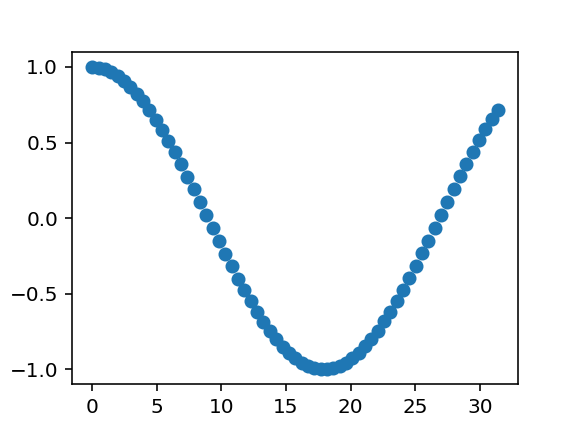

In [65]:
pn.pane.Matplotlib(draw_figure(n_points.value, freq.value, options.value))

In [71]:
import os
os.listdir("../../../Downloads/test.shp")

['.ipynb_checkpoints',
 '012023054-075.pdf',
 '10_ML_assignment_2 final.py',
 '11609.pdf',
 '13885458_1.pdf',
 '14-STS498.pdf',
 '2023-09-12_15th+Steering+Committee+Meeting.pptx',
 '2023-11-21 Kick-Out Meeting.pptx',
 '2023_SPIN_SC3_Thomas_Bodin_TransDimensional.pdf',
 '2024-02-19_documentdocx.docx',
 '2024-02-21_documentdocx.docx',
 '4136276_vanHeerden_P5presentation.pdf',
 '8-OedMF27w06mfSXg.png',
 '8-q2b4Ux9UWBTH7fy.png',
 '978-3-030-57097-2_4.pdf',
 '978-3-642-02658-4_34.pdf',
 '978-3-662-56655-8.pdf',
 '978-981-15-9908-8.pdf',
 '978-981-16-5312-4.pdf',
 '9781003047230_previewpdf.pdf',
 'Abstract_Maljers_Schokker_Stafleu_Gunnink_EGU_Vienna_2013.pdf',
 'Antrag.pdf',
 'Antragsdatei-nils_chudalla(at)eonerc_rwth-aachen_de-20231127_1211.json',
 'autompg.csv',
 'Balmuccia_gravity-modelling-challenge_DESCRIPTION.pdf',
 'BeFo_Report_155_webb.pdf',
 'Bereinigte Daten 20.01.2024.sav',
 'BIB_DE0005152631.pdf',
 'Bitwarden-Installer-2023.8.3.exe',
 'Blank Black.pdf',
 'blender-3.6.2-windows-x6

In [93]:
import geopandas as gpd
import shapely

In [72]:
gdf = gpd.read_file("../../../Downloads/test.shp")


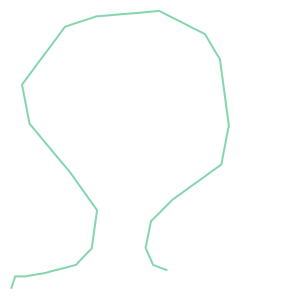

In [118]:
line = gdf.loc[0].geometry

lines = shapely.segmentize(line, max_segment_length=30)
lines

In [119]:
x = lines.coords.xy[0][:]
y = lines.coords.xy[1][:]

coords = np.vstack([x,y]).T
np.random.shuffle(coords)

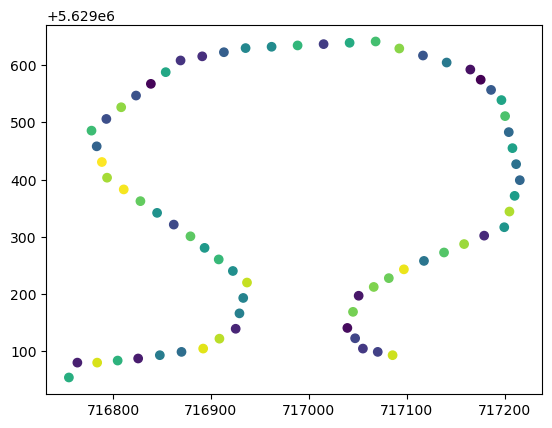

In [120]:
plt.scatter(coords[:,0], coords[:,1], c=np.arange(len(x)))

In [121]:
from scipy.spatial.distance import cdist

In [126]:
colors = np.zeros(len(x))
distances = cdist(coords, coords)

current_pos = np.argmin(coords[:,1])

value = 0
colors[current_pos] = value
value+=1

position = np.argmin(distances[current_pos, :])
distances[position:current_pos] = 1000
distances[current_pos:position] = 1000




#for i in range(len(x)-2):
    